# 01 — Data preparation and exploratory analysis

**Thesis:** *Crude Oil Volatility Regimes and Time-Varying Transition Probabilities: The Predictive Roles of Geopolitical Risk and Financial-Market Uncertainty*  
**Scope:** descriptive preparation only; no model estimation, selection, or hypothesis tests.

This notebook uses the four supplied, unchanged raw files. It constructs percentage log returns from consecutive **observed** oil prices, preserves missing observations and the negative WTI price for audit, joins predictors by date, and saves three analysis samples. Dates are daily and have no intraday timestamp. Re-run all cells after installing `pandas`, `numpy`, `xlrd`, and `matplotlib`. The notebook works when launched from the project root or `notebooks/`.

## 1. Setup and source provenance

The supplied CSVs are FRED downloads: Brent and WTI spot prices originate with the U.S. Energy Information Administration and are in USD per barrel; VIX is the CBOE volatility index. The supplied GPR workbook is the Caldara–Iacoviello **Recent** daily index. These are descriptions of the local files, not live downloads. Source pages: [Brent](https://fred.stlouisfed.org/series/DCOILBRENTEU), [WTI](https://fred.stlouisfed.org/series/DCOILWTICO), [VIX](https://fred.stlouisfed.org/series/VIXCLS), [GPR](https://www.matteoiacoviello.com/gpr.htm). The GPR authors advise citing the download date and warn that recent observations and some earlier history can be revised. The acquisition date of the supplied workbook is unknown, so its SHA-256 hash identifies this local vintage instead.

No unavailable price is filled, and no return is assigned to a holiday. All reported sample end dates are calculated from the supplied files.

In [1]:
from pathlib import Path
import hashlib
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xlrd
from IPython.display import display

PROJECT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
FIGURES = PROJECT / "results" / "figures"
assert RAW.is_dir(), f"Cannot find raw data at {RAW}"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

START = pd.Timestamp("2000-01-01")
TRAIN_END = pd.Timestamp("2015-12-31")
VALIDATION_END = pd.Timestamp("2019-12-31")

paths = {
    "Brent": RAW / "DCOILBRENTEU.csv",
    "WTI": RAW / "DCOILWTICO.csv",
    "VIX": RAW / "VIXCLS.csv",
    "GPR": RAW / "data_gpr_daily_recent.xls",
}
versions = pd.Series({
    "Python": platform.python_version(), "pandas": pd.__version__,
    "NumPy": np.__version__, "xlrd": xlrd.__version__,
    "Matplotlib": matplotlib.__version__,
}, name="version")
display(versions.to_frame())
display(pd.DataFrame([
    {"series": name, "raw_file": p.name, "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
    for name, p in paths.items()
]))

,version
Python,3.12.14
pandas,3.0.1
NumPy,2.5.4
xlrd,2.0.2
Matplotlib,3.11.2


,series,raw_file,sha256
0,Brent,DCOILBRENTEU.csv,f3ad22ec3aa8800fc5edfa638d364ae388a5612ed895d2...
1,WTI,DCOILWTICO.csv,d85c38f6f6e9078151ec4232b3c3653e8953bbd3b0506f...
2,VIX,VIXCLS.csv,7cfbdd416b37b45f1fb2ab7d476e9965aed3db8a402a25...
3,GPR,data_gpr_daily_recent.xls,a4cecd9b807b1cbf3db92e7a8087aaa23dafeb76b92f10...


## 2. Inspect raw structures and quality

We read dates explicitly to avoid locale-dependent parsing. The GPR workbook is inspected before selecting a series: its `DAY` field is `YYYYMMDD`, the `date` field is an Excel date, and `var_name`/`var_label` document the columns. `GPRD` is the daily headline index; `GPRD_ACT` and `GPRD_THREAT` are components, while `GPRD_MA7` and `GPRD_MA30` are already smoothed. We use unsmoothed `GPRD`. The two date fields must agree on every row.

The quality table distinguishes original rows from rows in the 2000–common-end window and usable values. A zero GPR index is a valid observed index value; strictly positive prices are required only for oil returns. Missing CSV values include FRED's blank entries. Duplicate or malformed dates halt execution because a date join would otherwise be ambiguous.

In [2]:
def read_fred(path, source_col, output_col):
    raw = pd.read_csv(path, dtype="string")
    assert list(raw.columns) == ["observation_date", source_col], (path.name, list(raw.columns))
    parsed = pd.DataFrame({
        "date": pd.to_datetime(raw["observation_date"], format="%Y-%m-%d", errors="coerce"),
        output_col: pd.to_numeric(raw[source_col], errors="coerce").astype(float),
    })
    return raw, parsed.sort_values("date").reset_index(drop=True)


brent_raw, brent_all = read_fred(paths["Brent"], "DCOILBRENTEU", "brent_price_usd_per_bbl")
wti_raw, wti_all = read_fred(paths["WTI"], "DCOILWTICO", "wti_price_usd_per_bbl")
vix_raw, vix_all = read_fred(paths["VIX"], "VIXCLS", "vix_index")

book = xlrd.open_workbook(paths["GPR"])
display(pd.DataFrame([{"sheet": s.name, "rows_including_header": s.nrows, "columns": s.ncols}
                      for s in book.sheets()]))
assert "Sheet1" in book.sheet_names()
gpr_raw = pd.read_excel(paths["GPR"], sheet_name="Sheet1", engine="xlrd")
display(pd.DataFrame({"column": gpr_raw.columns, "dtype": gpr_raw.dtypes.astype(str).values}))
display(gpr_raw.loc[gpr_raw["var_name"].notna(), ["var_name", "var_label"]].head(11))
assert {"DAY", "date", "GPRD"}.issubset(gpr_raw.columns)
gpr_day = pd.to_datetime(gpr_raw["DAY"].astype("string"), format="%Y%m%d", errors="coerce")
gpr_excel_date = pd.to_datetime(gpr_raw["date"], errors="coerce")
assert gpr_day.notna().all() and gpr_excel_date.notna().all()
assert gpr_day.eq(gpr_excel_date).all(), "GPR DAY and Excel date fields disagree"
gpr_all = pd.DataFrame({"date": gpr_day,
                        "gpr_index": pd.to_numeric(gpr_raw["GPRD"], errors="coerce")})
gpr_all = gpr_all.sort_values("date").reset_index(drop=True)

raw_frames = {"Brent": brent_raw, "WTI": wti_raw, "VIX": vix_raw, "GPR": gpr_raw}
series_frames = {"Brent": brent_all, "WTI": wti_all, "VIX": vix_all, "GPR": gpr_all}
value_cols = {"Brent": "brent_price_usd_per_bbl", "WTI": "wti_price_usd_per_bbl",
              "VIX": "vix_index", "GPR": "gpr_index"}

for name, frame in series_frames.items():
    if frame["date"].isna().any() or frame["date"].duplicated().any():
        raise ValueError(f"{name}: malformed or duplicate dates need manual review")

last_observed = {name: frame.loc[frame[col].notna(), "date"].max()
                 for name, frame in series_frames.items() for col in [value_cols[name]]}
COMMON_END = min(last_observed.values())
print("Latest nonmissing source dates:", {k: str(v.date()) for k, v in last_observed.items()})
print("Analysis window:", START.date(), "through", COMMON_END.date())

quality_rows = []
for name, frame in series_frames.items():
    col = value_cols[name]
    window = frame.loc[frame["date"].between(START, COMMON_END)]
    source_value = raw_frames[name]["GPRD" if name == "GPR" else
                                    {"Brent": "DCOILBRENTEU", "WTI": "DCOILWTICO", "VIX": "VIXCLS"}[name]]
    nonnumeric = source_value.notna() & pd.to_numeric(source_value, errors="coerce").isna()
    quality_rows.append({
        "series": name, "original_rows": len(frame),
        "first_raw_date": frame["date"].min().date(),
        "last_raw_date": frame["date"].max().date(),
        "invalid_dates": int(frame["date"].isna().sum()),
        "duplicate_dates": int(frame["date"].duplicated().sum()),
        "raw_missing_values": int(frame[col].isna().sum()),
        "raw_nonnumeric_nonblank": int(nonnumeric.sum()),
        "window_rows": len(window),
        "window_missing_values": int(window[col].isna().sum()),
        "window_negative_values": int(window[col].lt(0).sum()),
        "window_zero_values": int(window[col].eq(0).sum()),
        "window_usable_values": int((window[col].gt(0) if name in ("Brent", "WTI")
                                    else window[col].ge(0)).sum()),
        "weekend_date_rows": int(window["date"].dt.dayofweek.ge(5).sum()),
        "median_date_gap_days": frame["date"].diff().dt.days.median(),
        "maximum_date_gap_days": frame["date"].diff().dt.days.max(),
    })
quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv(PROCESSED / "01_data_quality_summary.csv", index=False)

,sheet,rows_including_header,columns
0,Sheet1,15275,11


,column,dtype
0,DAY,int64
1,N10D,int64
2,GPRD,float64
3,GPRD_ACT,float64
4,GPRD_THREAT,float64
5,date,datetime64[us]
6,GPRD_MA30,float64
7,GPRD_MA7,float64
8,event,str
9,var_name,str


,var_name,var_label
0,DAY,DAY
1,N10D,"Number of articles (10 recent newspapers, 1985-)"
2,GPRD,Daily GPR (Index: 1985:2019=100)
3,GPRD_ACT,Daily GPR Acts (Index: 1985:2019=100)
4,GPRD_THREAT,Daily GPR Threats (Index: 1985:2019=100)
5,date,Date
6,GPRD_MA30,30 day moving average of Daily GPR
7,GPRD_MA7,7 day moving average of Daily GPR
8,event,Major event label


Latest nonmissing source dates: {'Brent': '2026-10-27', 'WTI': '2026-10-27', 'VIX': '2026-10-29', 'GPR': '2026-10-26'}
Analysis window: 2000-01-01 through 2026-10-26


,series,original_rows,first_raw_date,last_raw_date,invalid_dates,duplicate_dates,raw_missing_values,raw_nonnumeric_nonblank,window_rows,window_missing_values,window_negative_values,window_zero_values,window_usable_values,weekend_date_rows,median_date_gap_days,maximum_date_gap_days
0,Brent,10290,1987-05-20,2026-10-27,0,0,1173,0,6996,501,0,0,6495,0,1.0,3.0
1,WTI,10649,1986-01-02,2026-10-27,0,0,1117,0,6996,650,1,0,6345,0,1.0,3.0
2,VIX,9608,1990-01-02,2026-10-29,0,0,302,0,6996,218,0,0,6778,0,1.0,3.0
3,GPR,15274,1985-01-01,2026-10-26,0,0,0,0,9796,0,0,1,9796,2800,1.0,1.0


## 3. Oil returns and the 20 April 2020 WTI observation

For consecutive **nonmissing observed** prices, $r_t=100\ln(P_t/P_{t-1})$, in percent. A missing holiday row does not become a zero return; the next observed price is compared with the previous observed price, and the gap in calendar days is retained. To calculate the first in-window return, its previous observed price may be before 1 January 2000; the resulting return date is inside the study window. If either price is nonpositive, the return is missing. Crucially, the negative WTI price stays in the observed-price sequence: deleting it before taking `shift(1)` would create a spurious return from 17 to 21 April 2020. The original negative price is retained in the audit output. No extreme valid return is automatically removed.

In [3]:
def prepare_oil_prices(frame, price_col, return_col):
    observed = frame.dropna(subset=[price_col]).copy().sort_values("date").reset_index(drop=True)
    observed[f"{price_col}_previous_observed"] = observed[price_col].shift(1)
    observed["previous_observed_date"] = observed["date"].shift(1)
    observed["observation_gap_calendar_days"] = (
        observed["date"] - observed["previous_observed_date"]).dt.days
    previous = observed[f"{price_col}_previous_observed"]
    valid = observed[price_col].gt(0) & previous.gt(0)
    observed[return_col] = np.nan
    observed.loc[valid, return_col] = 100 * np.log(
        observed.loc[valid, price_col] / previous.loc[valid])
    observed["return_valid"] = valid
    observed["return_exclusion_reason"] = np.select(
        [previous.isna(), observed[price_col].le(0), previous.le(0)],
        ["no previous observed price", "current price nonpositive", "previous price nonpositive"],
        default="",
    )
    return observed.loc[observed["date"].between(START, COMMON_END)].copy()


brent_audit = prepare_oil_prices(brent_all, "brent_price_usd_per_bbl", "brent_return_pct")
wti_audit = prepare_oil_prices(wti_all, "wti_price_usd_per_bbl", "wti_return_pct")
wti_audit.to_csv(PROCESSED / "01_wti_price_return_audit.csv", index=False,
                 date_format="%Y-%m-%d", float_format="%.10g")

display(wti_audit.loc[wti_audit["date"].between("2020-04-16", "2020-04-23"),
                      ["date", "wti_price_usd_per_bbl", "wti_price_usd_per_bbl_previous_observed",
                       "previous_observed_date", "wti_return_pct", "return_exclusion_reason"]])
assert wti_audit.loc[wti_audit["date"].eq("2020-04-20"), "wti_price_usd_per_bbl"].iloc[0] == -36.98
assert wti_audit.loc[wti_audit["date"].isin(pd.to_datetime(["2020-04-20", "2020-04-21"])),
                     "wti_return_pct"].isna().all()
assert wti_audit.loc[wti_audit["date"].eq("2020-04-22"), "wti_return_pct"].notna().all()

for name, audit, return_col in [("Brent", brent_audit, "brent_return_pct"),
                                ("WTI", wti_audit, "wti_return_pct")]:
    print(f"{name}: {len(audit):,} observed prices in window; "
          f"{audit[return_col].notna().sum():,} valid returns; "
          f"{audit['observation_gap_calendar_days'].gt(1).sum():,} price gaps >1 calendar day")
    display(audit.loc[audit[return_col].notna()].assign(
        absolute_return=lambda d: d[return_col].abs()
    ).nlargest(5, "absolute_return")[["date", return_col, "observation_gap_calendar_days"]])

,date,wti_price_usd_per_bbl,wti_price_usd_per_bbl_previous_observed,previous_observed_date,wti_return_pct,return_exclusion_reason
7898,2020-04-16,19.82,19.96,2020-04-15,-0.703874,
7899,2020-04-17,18.31,19.82,2020-04-16,-7.924417,
7900,2020-04-20,-36.98,18.31,2020-04-17,NaN,current price nonpositive
7901,2020-04-21,8.91,-36.98,2020-04-20,NaN,previous price nonpositive
7902,2020-04-22,13.64,8.91,2020-04-21,42.583241,
7903,2020-04-23,15.06,13.64,2020-04-22,9.903557,


Brent: 6,495 observed prices in window; 6,495 valid returns; 1,520 price gaps >1 calendar day


,date,brent_return_pct,observation_gap_calendar_days
7467,2020-04-21,-64.369891,1.0
7468,2020-04-22,41.202251,1.0
7456,2020-04-02,30.161265,1.0
7454,2020-03-31,-25.638944,1.0
7438,2020-03-09,-25.517526,3.0


WTI: 6,346 observed prices in window; 6,344 valid returns; 1,571 price gaps >1 calendar day


,date,wti_return_pct,observation_gap_calendar_days
7902,2020-04-22,42.583241,1.0
7887,2020-03-31,37.473777,1.0
7871,2020-03-09,-28.138208,3.0
7878,2020-03-18,-27.490549,1.0
7905,2020-04-27,-27.298962,3.0


## 4. Predictor timing and date alignment

`gpr_lag1_calendar_day` is the GPR value on **exactly the previous calendar date**; the GPR file has daily, including weekend, rows. `vix_lag1_observation` is the VIX value on the **previous nonmissing VIX observation**, which may be several calendar days earlier. We retain its source date and gap. This uses earlier reference dates, but a historical GPR reference date is not proof of when the value was published. The supplied GPR series is a revised vintage and must **not** be treated as a verified real-time information set. Same-day `gpr_index` and `vix_index` are retained for audit and descriptive use, not as predetermined transition covariates.

The complete-case analysis samples require a valid oil return and both original and lagged predictor values on the oil return date. Requiring same-day VIX avoids silently carrying it across a market closure. This may omit otherwise usable oil returns; the counts below quantify that loss. The maximum Brent sample retains all valid Brent returns, with missing predictors where their calendars do not align. No filling or interpolation occurs.

In [4]:
gpr = gpr_all.loc[gpr_all["date"].between(START - pd.Timedelta(days=1), COMMON_END),
                  ["date", "gpr_index"]].copy()
gpr_lag = gpr.rename(columns={"gpr_index": "gpr_lag1_calendar_day"}).copy()
gpr_lag["date"] += pd.Timedelta(days=1)

vix = vix_all.loc[vix_all["date"].le(COMMON_END), ["date", "vix_index"]].copy()
vix_observed = vix.dropna(subset=["vix_index"]).copy()
vix_observed["vix_lag1_observation"] = vix_observed["vix_index"].shift(1)
vix_observed["vix_lag_source_date"] = vix_observed["date"].shift(1)
vix_observed["vix_lag_gap_calendar_days"] = (
    vix_observed["date"] - vix_observed["vix_lag_source_date"]).dt.days

predictors = (gpr.merge(gpr_lag, on="date", how="outer", validate="one_to_one")
              .merge(vix_observed, on="date", how="outer", validate="one_to_one")
              .sort_values("date"))

def attach_predictors(oil_audit, return_col):
    usable = oil_audit.loc[oil_audit[return_col].notna()].drop(columns=["return_valid", "return_exclusion_reason"])
    return usable.merge(predictors, on="date", how="left", validate="one_to_one").sort_values("date").reset_index(drop=True)

brent_max = attach_predictors(brent_audit, "brent_return_pct")
wti_max = attach_predictors(wti_audit, "wti_return_pct")
required_predictors = ["gpr_index", "vix_index", "gpr_lag1_calendar_day", "vix_lag1_observation"]
brent_complete = brent_max.dropna(subset=required_predictors).reset_index(drop=True)
wti_robustness = wti_max.dropna(subset=required_predictors).reset_index(drop=True)

alignment = pd.DataFrame([
    {"oil": name, "valid_oil_returns": len(frame),
     "missing_same_day_GPR": int(frame["gpr_index"].isna().sum()),
     "missing_prior_calendar_day_GPR": int(frame["gpr_lag1_calendar_day"].isna().sum()),
     "missing_same_day_VIX": int(frame["vix_index"].isna().sum()),
     "missing_previous_observed_VIX": int(frame["vix_lag1_observation"].isna().sum()),
     "complete_case": int(frame[required_predictors].notna().all(axis=1).sum())}
    for name, frame in [("Brent", brent_max), ("WTI", wti_max)]
])
display(alignment)
print("GPR weekend observations in window:",
      int(gpr.loc[gpr["date"].between(START, COMMON_END), "date"].dt.dayofweek.ge(5).sum()))
oil_date_overlap = set(brent_max["date"]) & set(wti_max["date"])
print("Valid-return oil date overlap:", len(oil_date_overlap), "both;",
      len(brent_max) - len(oil_date_overlap), "Brent only;",
      len(wti_max) - len(oil_date_overlap), "WTI only")
print("VIX lag source gap distribution on complete Brent dates:")
display(brent_complete["vix_lag_gap_calendar_days"].value_counts().sort_index().to_frame("count"))

assert brent_max["date"].is_unique and brent_complete["date"].is_unique
assert (brent_complete["vix_lag_source_date"] < brent_complete["date"]).all()
assert brent_complete[required_predictors].notna().all().all()
gpr_lookup = gpr.set_index("date")["gpr_index"]
expected_gpr_lag = brent_complete["date"].sub(pd.Timedelta(days=1)).map(gpr_lookup)
assert np.allclose(brent_complete["gpr_lag1_calendar_day"], expected_gpr_lag)

,oil,valid_oil_returns,missing_same_day_GPR,missing_prior_calendar_day_GPR,missing_same_day_VIX,missing_previous_observed_VIX,complete_case
0,Brent,6495,0,0,85,85,6410
1,WTI,6344,0,0,8,8,6336


GPR weekend observations in window: 2800
Valid-return oil date overlap: 6052 both; 443 Brent only; 292 WTI only
VIX lag source gap distribution on complete Brent dates:


,count
vix_lag_gap_calendar_days,
1.0,5078
2.0,48
3.0,1155
4.0,127
5.0,2


## 5. Chronological periods and saved analysis samples

Training is 2000–2015, validation 2016–2019, and testing 2020–the common end date. The 2020–end test period is defined now but no model is fitted or selected here. There is **no standardization in this notebook**: original GPR and VIX index units are preserved. If later modelling needs scaling, fit its parameters on training observations only, then apply those fixed parameters to validation and test data.

In [5]:
def split_label(dates):
    return np.select([dates.le(TRAIN_END), dates.le(VALIDATION_END)],
                     ["train", "validation"], default="test")

samples = {"brent_max": brent_max, "brent_complete_case": brent_complete,
           "wti_robustness": wti_robustness}
sample_rows = []
for name, frame in samples.items():
    assert not frame.empty
    frame["split"] = split_label(frame["date"])
    frame.to_csv(PROCESSED / f"01_{name}.csv", index=False,
                 date_format="%Y-%m-%d", float_format="%.10g")
    sample_rows.append({"sample": name, "observations": len(frame),
                        "first_date": frame["date"].min().date(),
                        "last_date": frame["date"].max().date(),
                        "train": int(frame["split"].eq("train").sum()),
                        "validation": int(frame["split"].eq("validation").sum()),
                        "test": int(frame["split"].eq("test").sum())})
sample_summary = pd.DataFrame(sample_rows)
display(sample_summary)
sample_summary.to_csv(PROCESSED / "01_sample_summary.csv", index=False)

for name, frame in samples.items():
    assert frame["date"].between(START, COMMON_END).all()
    assert frame["date"].is_monotonic_increasing
    assert frame["split"].eq(split_label(frame["date"])).all()
assert set(brent_complete["date"]).issubset(set(brent_max["date"]))
assert set(wti_robustness["date"]).issubset(set(wti_max["date"]))

,sample,observations,first_date,last_date,train,validation,test
0,brent_max,6495,2000-01-04,2026-10-26,3750,1020,1725
1,brent_complete_case,6410,2000-01-04,2026-10-26,3699,999,1712
2,wti_robustness,6336,2000-01-04,2026-10-26,3633,1000,1703


## 6. Descriptive statistics and figures

The statistics use each oil's **maximum valid return** sample, so WTI is not restricted to days with both predictors. Standard deviation is the sample standard deviation (`ddof=1`). The 30-observation Brent rolling volatility is the sample standard deviation of the last 30 valid daily returns, in **percentage points per day**; it is not annualized. The plots show all retained extreme valid observations without trimming. They describe the data and do not constitute a test of regime changes.

In [6]:
def describe_returns(series):
    q = series.quantile([.01, .99])
    return pd.Series({"n": int(series.count()), "mean_pct": series.mean(),
                      "median_pct": series.median(), "sd_pct": series.std(ddof=1),
                      "min_pct": series.min(), "p01_pct": q.loc[.01],
                      "p99_pct": q.loc[.99], "max_pct": series.max(),
                      "skewness": series.skew(), "excess_kurtosis": series.kurt()})

descriptive = pd.DataFrame({
    "Brent": describe_returns(brent_max["brent_return_pct"]),
    "WTI": describe_returns(wti_max["wti_return_pct"]),
}).T
display(descriptive.round(3))
descriptive.to_csv(PROCESSED / "01_return_descriptive_statistics.csv", float_format="%.10g")

brent_max["brent_rolling_volatility_30obs_pct"] = (
    brent_max["brent_return_pct"].rolling(window=30, min_periods=30).std(ddof=1))

,n,mean_pct,median_pct,sd_pct,min_pct,p01_pct,p99_pct,max_pct,skewness,excess_kurtosis
Brent,6495.0,0.025,0.067,2.738,-64.370,-7.10,6.859,41.202,-1.726,64.158
WTI,6344.0,0.034,0.120,2.847,-28.138,-7.59,7.177,42.583,0.308,24.094


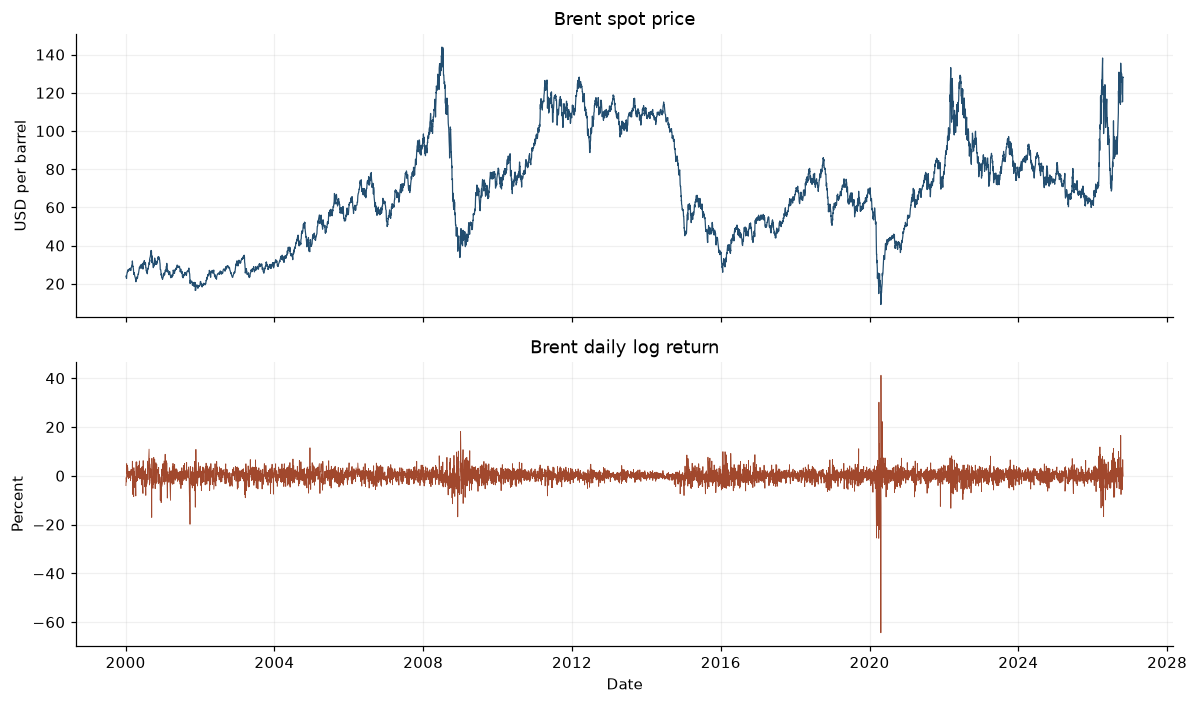

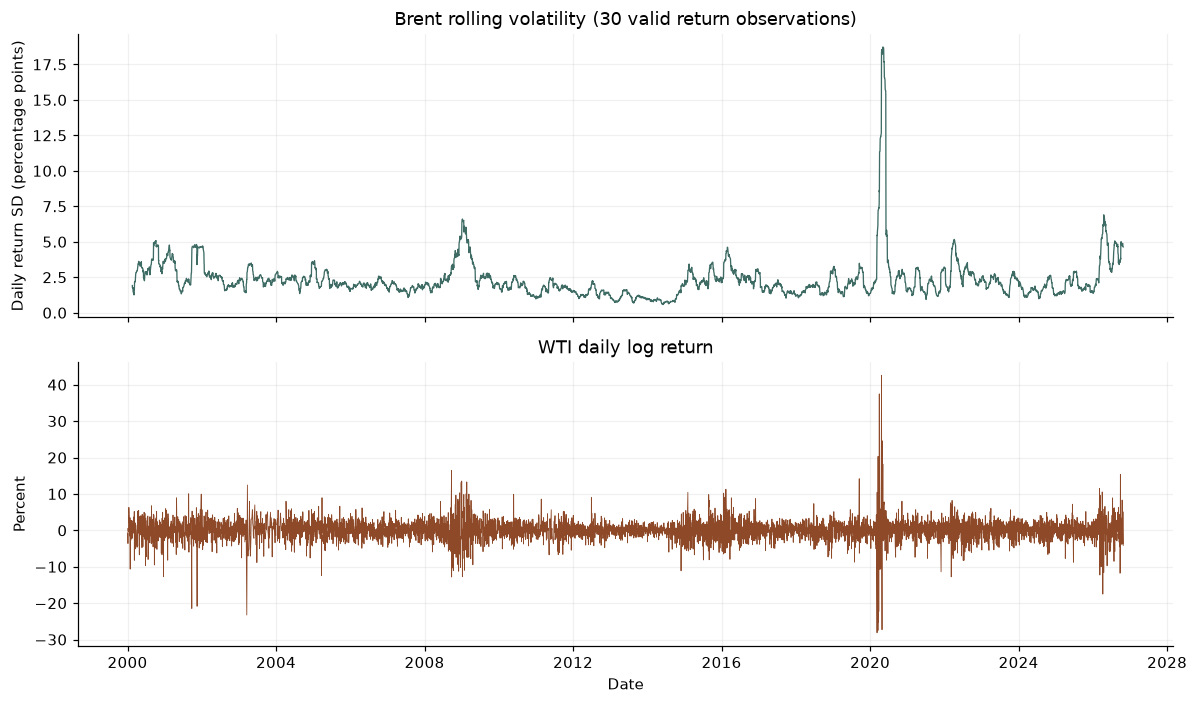

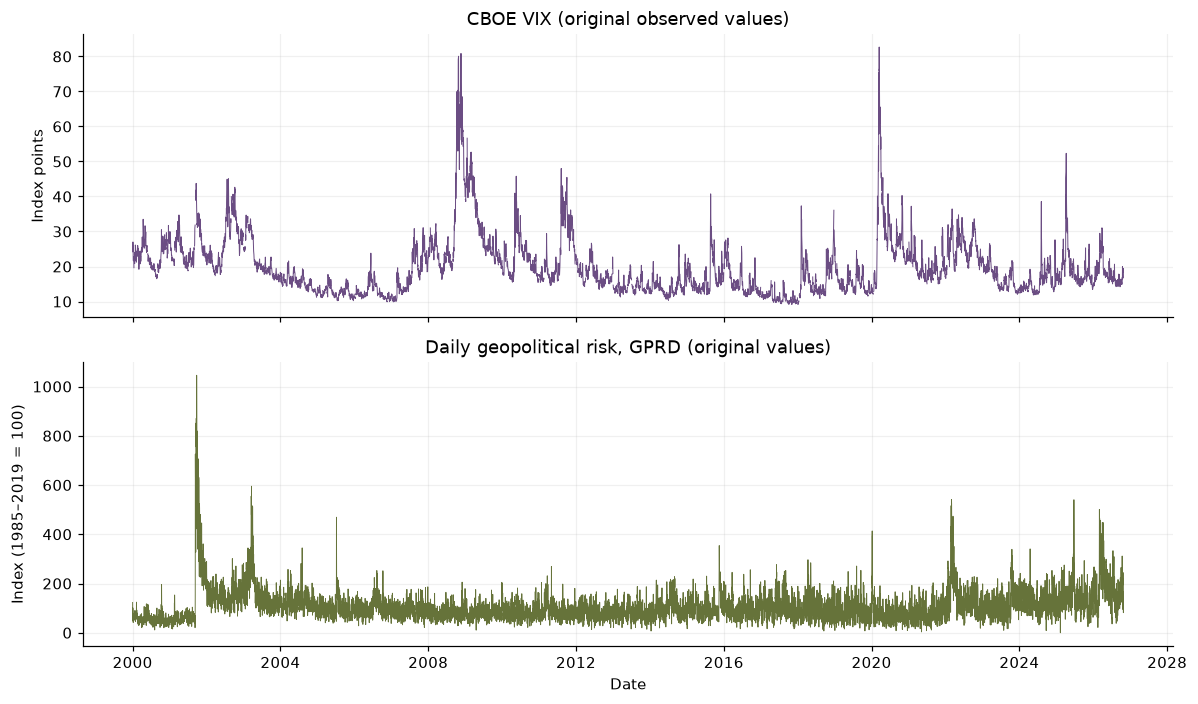

In [7]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def finish_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(brent_max["date"], brent_max["brent_price_usd_per_bbl"], lw=.8, color="#234e70")
ax[0].set(title="Brent spot price", ylabel="USD per barrel")
ax[1].plot(brent_max["date"], brent_max["brent_return_pct"], lw=.55, color="#a1482d")
ax[1].set(title="Brent daily log return", ylabel="Percent", xlabel="Date")
for a in ax: a.grid(alpha=.18)
finish_figure(fig, "01_brent_price_returns.png")

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(brent_max["date"], brent_max["brent_rolling_volatility_30obs_pct"],
           lw=.85, color="#3e6c65")
ax[0].set(title="Brent rolling volatility (30 valid return observations)",
          ylabel="Daily return SD (percentage points)")
ax[1].plot(wti_max["date"], wti_max["wti_return_pct"], lw=.55, color="#8e4928")
ax[1].set(title="WTI daily log return", ylabel="Percent", xlabel="Date")
for a in ax: a.grid(alpha=.18)
finish_figure(fig, "01_rolling_volatility_wti_returns.png")

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
vix_plot = vix_all.loc[vix_all["date"].between(START, COMMON_END)]
gpr_plot = gpr_all.loc[gpr_all["date"].between(START, COMMON_END)]
ax[0].plot(vix_plot["date"], vix_plot["vix_index"], lw=.65, color="#6b4d83")
ax[0].set(title="CBOE VIX (original observed values)", ylabel="Index points")
ax[1].plot(gpr_plot["date"], gpr_plot["gpr_index"], lw=.6, color="#66733a")
ax[1].set(title="Daily geopolitical risk, GPRD (original values)",
          ylabel="Index (1985–2019 = 100)", xlabel="Date")
for a in ax: a.grid(alpha=.18)
finish_figure(fig, "01_vix_gpr.png")

## 7. Checks and interpretation for later modelling

The checks below independently recompute one return, verify date and lag relationships, and re-read the saved samples. The WTI price audit contains the `-36.98` USD/barrel price and records why the 20 and 21 April 2020 returns are undefined. The GPR index is a revised historical series; even one-day-lagged GPR is **not** a validated publication-time information set. Oil, VIX, and GPR have different calendars. The complete-case samples select dates on which both same-day source values and both lagged values exist; missing days are not imputed. These choices and the late sample end may matter when forecasting rules are developed later.

In [8]:
probe = brent_max.iloc[100]
manual_return = 100 * np.log(probe["brent_price_usd_per_bbl"] /
                             probe["brent_price_usd_per_bbl_previous_observed"])
assert np.isclose(probe["brent_return_pct"], manual_return)
assert not brent_max["brent_return_pct"].isna().any()
assert not wti_max["wti_return_pct"].isna().any()
assert not wti_audit.loc[wti_audit["date"].eq("2020-04-20"), "wti_return_pct"].notna().any()

for name, frame in samples.items():
    reread = pd.read_csv(PROCESSED / f"01_{name}.csv", parse_dates=["date"])
    assert len(reread) == len(frame) and reread["date"].equals(frame["date"])
    assert reread["split"].equals(frame["split"])

print("All return, alignment, split, and saved-file checks passed.")
print("Final sample counts:")
display(sample_summary[["sample", "observations", "first_date", "last_date"]])
print("Main data-quality issues within the study window:")
display(quality[["series", "window_missing_values", "window_negative_values",
                 "window_zero_values", "weekend_date_rows"]])
print("Cleaning: no price filling or zero holiday returns; returns require two positive")
print("consecutive observed prices; negative WTI price retained in audit and two")
print("affected WTI returns are undefined; complete cases require both original")
print("and lagged predictors; no scaling or extreme-value trimming was applied.")
print("Limitations: GPR is a revised historical vintage with unknown publication timing;")
print("source trading calendars differ, so complete-case selection omits oil dates;")
print("the first in-window return may use a pre-2000 previous observed price.")
print("Generated files:")
print("  ", (PROJECT / "notebooks" / "01_data_preparation.ipynb").relative_to(PROJECT))
for path in sorted(PROCESSED.glob("01_*.csv")):
    print("  ", path.relative_to(PROJECT))
for path in sorted(FIGURES.glob("01_*.png")):
    print("  ", path.relative_to(PROJECT))

All return, alignment, split, and saved-file checks passed.
Final sample counts:


,sample,observations,first_date,last_date
0,brent_max,6495,2000-01-04,2026-10-26
1,brent_complete_case,6410,2000-01-04,2026-10-26
2,wti_robustness,6336,2000-01-04,2026-10-26


Main data-quality issues within the study window:


,series,window_missing_values,window_negative_values,window_zero_values,weekend_date_rows
0,Brent,501,0,0,0
1,WTI,650,1,0,0
2,VIX,218,0,0,0
3,GPR,0,0,1,2800


Cleaning: no price filling or zero holiday returns; returns require two positive
consecutive observed prices; negative WTI price retained in audit and two
affected WTI returns are undefined; complete cases require both original
and lagged predictors; no scaling or extreme-value trimming was applied.
Limitations: GPR is a revised historical vintage with unknown publication timing;
source trading calendars differ, so complete-case selection omits oil dates;
the first in-window return may use a pre-2000 previous observed price.
Generated files:
   notebooks\01_data_preparation.ipynb
   data\processed\01_brent_complete_case.csv
   data\processed\01_brent_max.csv
   data\processed\01_data_quality_summary.csv
   data\processed\01_return_descriptive_statistics.csv
   data\processed\01_sample_summary.csv
   data\processed\01_wti_price_return_audit.csv
   data\processed\01_wti_robustness.csv
   results\figures\01_brent_price_returns.png
   results\figures\01_rolling_volatility_wti_returns.png
 